# Task 3: Quantitative Evaluation
  Dice, HD95 and HD for Swin UNETR Base / Small / Tiny on the 6 BTCV validation scans



In [40]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import BTCV_ORGANS, FIGURES_DIR, METRICS_DIR, MODEL_CONFIGS
from src.evaluate import evaluate_model

pd.set_option("display.precision", 3)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["tiny", "small", "base"]
MODEL_NAMES = {m: MODEL_CONFIGS[m]["name"] for m in MODELS}
MODEL_COLORS = {"tiny": "#eb6834", "small": "#1baf7a", "base": "#2a78d6"}  # fixed colour per model
ORGANS = list(BTCV_ORGANS.values())
OVERLAP = 0.5
RECOMPUTE = False  # True = recompute metrics even if the CSV already exists

plt.style.use("default")  # white background for the report (IDE dark theme otherwise leaks into saved figures)

In [41]:
# Compute or load metrics for all models
dfs = []
for m in MODELS:
    csv = METRICS_DIR / f"btcv_metrics_{m}_overlap{OVERLAP}.csv"
    if csv.exists() and not RECOMPUTE:
        print(f"[LOAD] {csv.name}")
        dfs.append(pd.read_csv(csv))
    else:
        print(f"[COMPUTE] {m} ...")
        dfs.append(evaluate_model(m, infer_overlap=OVERLAP))
df = pd.concat(dfs, ignore_index=True)
df["missed"] = df["organ_in_gt"] & df["hd95"].isna()  # organ exists but model predicted nothing
df.head()

[LOAD] btcv_metrics_tiny_overlap0.5.csv
[LOAD] btcv_metrics_small_overlap0.5.csv
[LOAD] btcv_metrics_base_overlap0.5.csv


,model,case,organ,dice,hd95,hd,organ_in_gt,missed
0,tiny,img0035.nii.gz,Spleen,0.937,4.114,401.177,True,False
1,tiny,img0035.nii.gz,Right Kidney,0.928,5.063,401.148,True,False
2,tiny,img0035.nii.gz,Left Kidney,0.932,3.793,350.858,True,False
3,tiny,img0035.nii.gz,Gallbladder,0.000,NaN,NaN,False,False
4,tiny,img0035.nii.gz,Esophagus,0.603,15.599,21.973,True,False


In [42]:
# Check that Dice matches Task 2
for m in MODELS:
    task2 = pd.read_csv(METRICS_DIR / f"btcv_dice_{m}_overlap{OVERLAP}.csv")["mean_dice"].mean() * 100
    task3 = df[df.model == m].groupby("case")["dice"].mean().mean() * 100
    print(f"{MODEL_NAMES[m]:20s} Task 2: {task2:.2f}   Task 3: {task3:.2f}   {'OK' if abs(task2 - task3) < 1e-6 else 'MISMATCH'}")

Swin UNETR / Tiny    Task 2: 66.31   Task 3: 66.31   OK
Swin UNETR / Small   Task 2: 77.89   Task 3: 77.89   OK
Swin UNETR / Base    Task 2: 81.37   Task 3: 81.37   OK


In [43]:
# Overall performance per model
# Mean Dice uses the official definition (mean over 13 organs, then over 6 scans; absent organs count as 0)
# HD95 / HD are averaged only where both masks exist (NaN = undefined); missed organs are counted separately
case_means = df.groupby(["model", "case"])["dice"].mean()
overall = pd.DataFrame({
    "Dice [%]": case_means.groupby("model").mean() * 100,
    "Dice std over scans [%]": case_means.groupby("model").std() * 100,
    "Paper Dice [%]": pd.Series({m: MODEL_CONFIGS[m][f"paper_dice_{str(OVERLAP).replace('0.', '0')}"] for m in MODELS}),
    "HD95 mean [mm]": df.groupby("model")["hd95"].mean(),
    "HD95 median [mm]": df.groupby("model")["hd95"].median(),
    "HD mean [mm]": df.groupby("model")["hd"].mean(),
    "Missed organs (of 78)": df.groupby("model")["missed"].sum(),
}).loc[MODELS].rename(index=MODEL_NAMES)
overall.to_csv(METRICS_DIR / f"task3_overall_overlap{OVERLAP}.csv")
overall

,Dice [%],Dice std over scans [%],Paper Dice [%],HD95 mean [mm],HD95 median [mm],HD mean [mm],Missed organs (of 78)
Swin UNETR / Tiny,66.308,4.147,70.35,104.719,26.418,252.775,6
Swin UNETR / Small,77.886,4.252,79.34,111.932,12.384,273.426,0
Swin UNETR / Base,81.372,2.971,81.86,43.645,6.363,198.106,0


In [44]:
# Performance per organ
# Only scans where the organ exists in the ground truth
present = df[df.organ_in_gt]
organ_dice = present.pivot_table(index="organ", columns="model", values="dice", aggfunc="mean").loc[ORGANS, MODELS]
organ_hd95 = present.pivot_table(index="organ", columns="model", values="hd95", aggfunc="median").loc[ORGANS, MODELS]
organ_table = pd.concat(
    {"Dice (mean)": organ_dice.rename(columns=MODEL_NAMES), "HD95 median [mm]": organ_hd95.rename(columns=MODEL_NAMES)},
    axis=1,
)
organ_table.to_csv(METRICS_DIR / f"task3_organwise_overlap{OVERLAP}.csv")
organ_table.sort_values(("Dice (mean)", MODEL_NAMES["base"]), ascending=False)

Dice (mean)                     \
model                    Swin UNETR / Tiny Swin UNETR / Small   
organ                                                           
Liver                                0.923              0.952   
Spleen                               0.902              0.929   
Right Kidney                         0.924              0.935   
Left Kidney                          0.921              0.931   
Aorta                                0.819              0.867   
Inferior Vena Cava                   0.778              0.826   
Pancreas                             0.655              0.705   
Stomach                              0.709              0.730   
Gallbladder                          0.663              0.717   
Portal and Splenic Veins             0.677              0.704   
Esophagus                            0.644              0.705   
Right Adrenal Gland                  0.000              0.656   
Left Adrenal Gland                   0.116              0.586   

                                            HD95 median [mm]  \
model                    Swin UNETR / Base Swin UNETR / Tiny   
organ                                                          
Liver                                0.960           272.683   
Spleen                               0.952            12.117   
Right Kidney                         0.933            64.357   
Left Kidney                          0.930            10.810   
Aorta                                0.900           218.277   
Inferior Vena Cava                   0.828            22.769   
Pancreas                             0.820            15.931   
Stomach                              0.778           312.378   
Gallbladder                          0.768            11.233   
Portal and Splenic Veins             0.759            20.796   
Esophagus                            0.749            13.073   
Right Adrenal Gland                  0.691               NaN   
Left Adrenal Gland                   0.638            48.252   

                                                               
model                    Swin UNETR / Small Swin UNETR / Base  
organ                                                          
Liver                               291.947           124.157  
Spleen                              400.051           110.635  
Right Kidney                        221.682             2.925  
Left Kidney                           5.107             4.430  
Aorta                                18.598             5.000  
Inferior Vena Cava                    9.161            15.694  
Pancreas                             11.828             6.802  
Stomach                             348.608            25.579  
Gallbladder                           7.461             5.000  
Portal and Splenic Veins             13.241            11.262  
Esophagus                             9.886             6.360  
Right Adrenal Gland                   5.941             4.492  
Left Adrenal Gland                    8.654             6.827

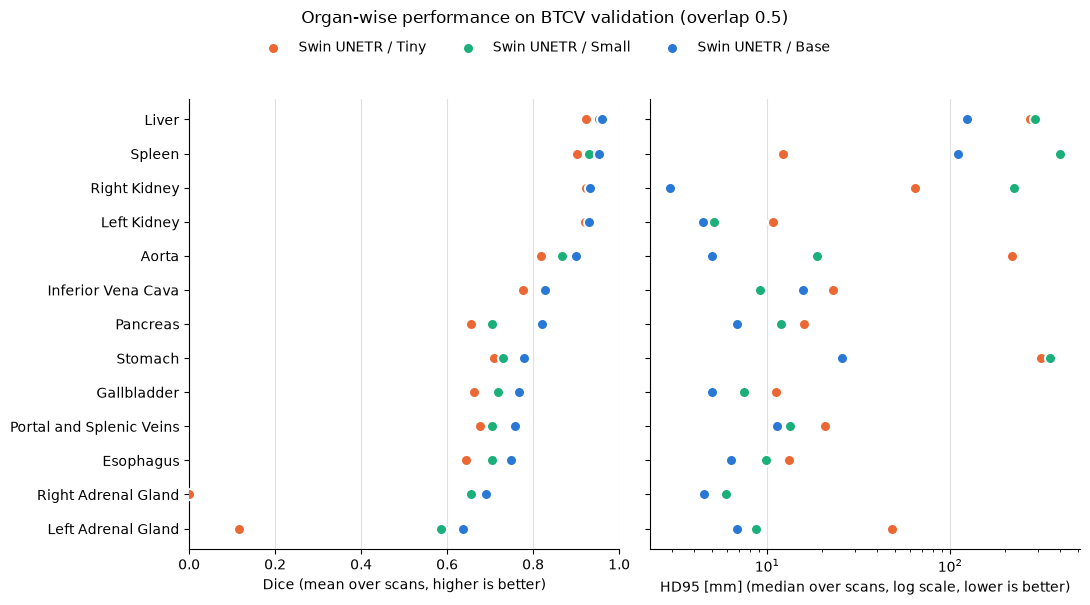

In [45]:
# Plot of Dice and HD95 per organ
order = organ_dice["base"].sort_values().index  # easiest organ at the top
y = np.arange(len(order))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6), sharey=True)

for m in MODELS:
    style = dict(color=MODEL_COLORS[m], label=MODEL_NAMES[m], s=64, zorder=3, edgecolor="white", linewidth=1.5)
    ax1.scatter(organ_dice.loc[order, m], y, **style)
    ax2.scatter(organ_hd95.loc[order, m], y, **style)

ax1.set_yticks(y, order)
ax1.set_xlabel("Dice (mean over scans, higher is better)")
ax1.set_xlim(0, 1)
ax2.set_xscale("log")
ax2.set_xlabel("HD95 [mm] (median over scans, log scale, lower is better)")

for ax in (ax1, ax2):
    ax.grid(axis="x", color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.legend(*ax1.get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.97))
fig.suptitle("Organ-wise performance on BTCV validation (overlap 0.5)", y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGURES_DIR / "task3_organwise.png", dpi=200, bbox_inches="tight", pad_inches=0.2)

plt.show()

In [46]:
# Best and worst example
per_case = df.groupby(["model", "case"]).agg(
      dice=("dice", "mean"), hd95=("hd95", "mean"), hd95_median=("hd95", "median"), missed=("missed", "sum")
  ).reset_index()
best = per_case.loc[per_case["dice"].idxmax()]
worst = per_case.loc[per_case["dice"].idxmin()]
for label, row in (("Best", best), ("Worst", worst)):
    print(f"{label:5s}: {MODEL_NAMES[row.model]} / {row.case}  Dice = {row.dice * 100:.2f}%  "
            f"HD95 mean = {row.hd95:.1f} mm  (median {row.hd95_median:.1f} mm)  missed organs = {row.missed}")
per_case.sort_values("dice", ascending=False)

Best : Swin UNETR / Base / img0039.nii.gz  Dice = 83.82%  HD95 mean = 86.5 mm  (median 7.4 mm)  missed organs = 0
Worst: Swin UNETR / Tiny / img0038.nii.gz  Dice = 60.18%  HD95 mean = 199.7 mm  (median 222.6 mm)  missed organs = 1


,model,case,dice,hd95,hd95_median,missed
4,base,img0039.nii.gz,0.838,86.500,7.433,0
1,base,img0036.nii.gz,0.833,51.557,6.000,0
2,base,img0037.nii.gz,0.831,11.182,6.363,0
5,base,img0040.nii.gz,0.829,7.096,4.752,0
10,small,img0039.nii.gz,0.824,184.932,15.000,0
11,small,img0040.nii.gz,0.805,103.591,15.668,0
7,small,img0036.nii.gz,0.800,43.846,9.005,0
8,small,img0037.nii.gz,0.792,52.503,9.317,0
3,base,img0038.nii.gz,0.782,35.498,6.176,0
0,base,img0035.nii.gz,0.770,72.236,15.740,0


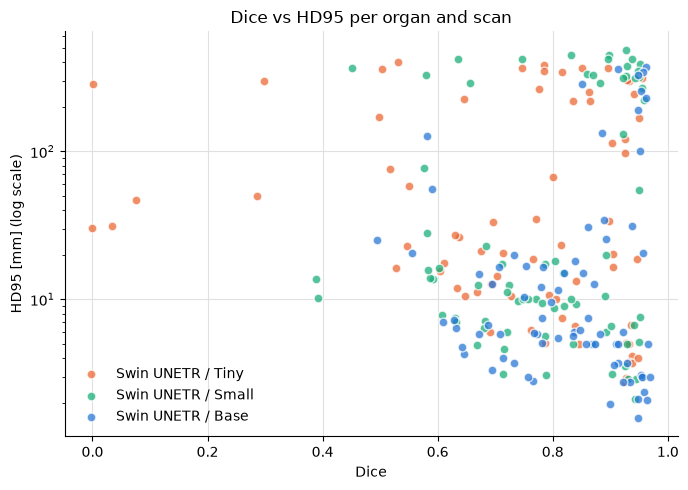

Spearman correlation Dice vs HD95: -0.11


,Rank by Dice,Rank by HD95 median,Rank by HD95 mean
Swin UNETR / Tiny,3,3,2
Swin UNETR / Small,2,2,3
Swin UNETR / Base,1,1,1


In [47]:
# Do Dice and HD95 agree?
fig, ax = plt.subplots(figsize=(7, 5))
for m in MODELS:
    d = df[(df.model == m) & df.hd95.notna()]
    ax.scatter(d["dice"], d["hd95"], color=MODEL_COLORS[m], label=MODEL_NAMES[m], s=40, alpha=0.75,
               edgecolor="white", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Dice")
ax.set_ylabel("HD95 [mm] (log scale)")
ax.set_title("Dice vs HD95 per organ and scan")
ax.grid(color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task3_dice_vs_hd95.png", dpi=200, bbox_inches="tight", pad_inches=0.2)

plt.show()

rank = pd.DataFrame({
    "Rank by Dice": overall["Dice [%]"].rank(ascending=False).astype(int),
    "Rank by HD95 median": overall["HD95 median [mm]"].rank().astype(int),
    "Rank by HD95 mean": overall["HD95 mean [mm]"].rank().astype(int),
})

print("Spearman correlation Dice vs HD95:", round(df[["dice", "hd95"]].corr(method="spearman").iloc[0, 1], 2))
rank